<a href="https://colab.research.google.com/github/alfatih241/stroke-prediction/blob/main/Kelompok5_Week2_MLP_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MINGGU 2: DATA PREPROCESSING & ARSITEKTUR BASELINE MLP
**Kelompok 5 - Deep Learning C**
- M. Alfatih
- Nisa Aulia Kirani
- Didy Ardiyanto

**Topik:** Klasifikasi Risiko Penyakit Stroke Menggunakan Multilayer Perceptron (MLP) dengan Penanganan Imbalanced Data Berbasis SMOTE

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# Load dataset langsung dari GitHub
url = 'https://raw.githubusercontent.com/alfatih241/stroke-prediction/main/healthcare-dataset-stroke-data.csv'
df = pd.read_csv(url, sep=';')

print("Dataset berhasil dimuat!")
df.head()

Dataset berhasil dimuat!


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [2]:
# 1. Hapus kolom 'id'
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# 2. Cleaning Missing Value pada 'bmi' menggunakan Median
df['bmi'] = df['bmi'].fillna(df['bmi'].median())

# 3. Hapus baris 'Other' pada gender
df = df[df['gender'] != 'Other']

# 4. Feature Engineering: One-Hot Encoding variabel kategorikal
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

print("Bentuk dataset setelah cleaning & encoding:", df_encoded.shape)
df_encoded.head()

Bentuk dataset setelah cleaning & encoding: (5109, 16)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,1,1,0,1,0,0,1,1,0,0
1,61.0,0,0,202.21,28.1,1,0,1,0,0,1,0,0,0,1,0
2,80.0,0,1,105.92,32.5,1,1,1,0,1,0,0,0,0,1,0
3,49.0,0,0,171.23,34.4,1,0,1,0,1,0,0,1,0,0,1
4,79.0,1,0,174.12,24.0,1,0,1,0,0,1,0,0,0,1,0


In [3]:
X = df_encoded.drop(columns=['stroke'])
y = df_encoded['stroke']

# Split Data (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Penyeimbangan Kelas dengan SMOTE (Hanya pada Data Latih)
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print(f"Distribusi y_train sebelum SMOTE : {np.bincount(y_train)}")
print(f"Distribusi y_train setelah SMOTE  : {np.bincount(y_train_res)}")

Distribusi y_train sebelum SMOTE : [3888  199]
Distribusi y_train setelah SMOTE  : [3888 3888]


In [4]:
# Merancang Model Baseline MLP Sederhana
input_dim = X_train_res.shape[1]

model = Sequential([
    Dense(32, input_dim=input_dim, activation='relu', name='Hidden_1'),
    Dropout(0.2),
    Dense(16, activation='relu', name='Hidden_2'),
    Dropout(0.2),
    Dense(1, activation='sigmoid', name='Output')
], name="Baseline_MLP_Stroke")

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Recall(name='recall')]
)

model.summary()

# Pelatihan Model Awal
history = model.fit(
    X_train_res, y_train_res,
    epochs=50,
    batch_size=32,
    validation_split=0.15,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Baseline_MLP_Stroke"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_1 (Dense)                │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,057 (4.13 KB)

 Trainable params: 1,057 (4.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6703 - loss: 0.5955 - recall: 0.5968 - val_accuracy: 0.6795 - val_loss: 0.6145 - val_recall: 0.6795
Epoch 2/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7458 - loss: 0.4903 - recall: 0.7031 - val_accuracy: 0.7823 - val_loss: 0.5609 - val_recall: 0.7823
Epoch 3/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7688 - loss: 0.4581 - recall: 0.7585 - val_accuracy: 0.8406 - val_loss: 0.4921 - val_recall: 0.8406
Epoch 4/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7844 - loss: 0.4411 - recall: 0.7964 - val_accuracy: 0.8535 - val_loss: 0.4813 - val_recall: 0.8535
Epoch 5/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7859 - loss: 0.4313 - recall: 0.8122 - val_accuracy: 0.8809 - val_loss: 0.4495 - val_recall: 0.8809
Epoch 6/50
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7980 - loss: 0.4192 - recall: 0.8280 - val_accuracy: 0.8698 - val_loss: 0.4539 - val_recall: 0.8698
Epoc

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
=== HASIL EVALUASI MODEL BASELINE (WEEK 2) ===
Accuracy  : 84.05%
Precision : 15.34%
Recall    : 50.00%
F1-Score  : 23.47%

              precision    recall  f1-score   support

  Non-Stroke       0.97      0.86      0.91       972
      Stroke       0.15      0.50      0.23        50

    accuracy                           0.84      1022
   macro avg       0.56      0.68      0.57      1022
weighted avg       0.93      0.84      0.88      1022



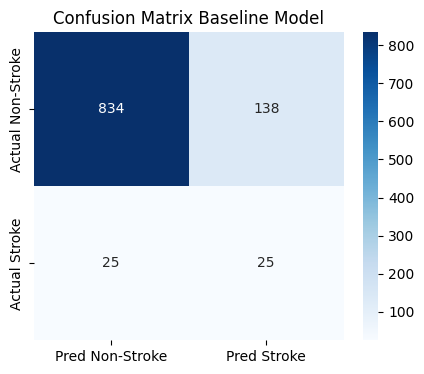

In [5]:
# Prediksi data uji
y_pred_proba = model.predict(X_test_scaled)
y_pred = (y_pred_proba > 0.5).astype(int)

# Metrik Evaluasi Awal
print("=== HASIL EVALUASI MODEL BASELINE (WEEK 2) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred) * 100:.2f}%")
print(f"Precision : {precision_score(y_test, y_pred) * 100:.2f}%")
print(f"Recall    : {recall_score(y_test, y_pred) * 100:.2f}%")
print(f"F1-Score  : {f1_score(y_test, y_pred) * 100:.2f}%\n")

print(classification_report(y_test, y_pred, target_names=['Non-Stroke', 'Stroke']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred Non-Stroke', 'Pred Stroke'],
            yticklabels=['Actual Non-Stroke', 'Actual Stroke'])
plt.title('Confusion Matrix Baseline Model')
plt.show()